# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [3]:
df.describe()

,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  str    
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  str    
 6   occupation   100000 non-null  str    
 7   zip_code     100000 non-null  str    
 8   title        100000 non-null  str    
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  str    
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 9.9 MB


In [5]:
df.shape

(100000, 13)

In [6]:
df.isnull().sum()

user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64

In [7]:
print(df.shape)
df = df.dropna()

print(df.shape)
df.isnull().sum()

(100000, 13)
(99970, 13)


user_id        0
movie_id       0
rating         0
timestamp      0
age            0
gender         0
occupation     0
zip_code       0
title          0
year           0
decade         0
genres         0
rating_year    0
dtype: int64

print(df.duplicated().sum())

In [8]:
print(df.duplicated().sum())
#No dupes

0


In [9]:
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


In [10]:
df['genres'].value_counts(ascending=True)

genres
unknown                   1
Fantasy                   1
Comedy|Documentary        1
Crime|Film-Noir           4
Comedy|Crime|Drama        5
                      ...  
Action|Thriller        3550
Drama|Romance          4767
Comedy|Romance         5055
Comedy                 9828
Drama                 13256
Name: count, Length: 216, dtype: int64

In [11]:
unknownRow = df[df['genres'] == 'unknown']
unknownRow.head()
unknownRow.loc[8567, 'genres'] = 'Drama|Comedy'
unknownRow.head()
df.loc[8567, 'genres'] = 'Comedy|Drama'

In [12]:
df['genres'].value_counts(ascending=True)

genres
Fantasy                          1
Comedy|Documentary               1
Crime|Film-Noir                  4
Comedy|Crime|Drama               5
Action|Adventure|Children        5
                             ...  
Action|Thriller               3550
Drama|Romance                 4767
Comedy|Romance                5055
Comedy                        9828
Drama                        13256
Name: count, Length: 215, dtype: int64

In [13]:
df['occupation'].value_counts()

occupation
student          21954
other            10661
educator          9439
engineer          8172
programmer        7798
administrator     7477
writer            5533
librarian         5273
technician        3505
executive         3402
healthcare        2801
artist            2307
entertainment     2093
scientist         2057
marketing         1950
retired           1608
lawyer            1345
none               900
salesman           856
doctor             540
homemaker          299
Name: count, dtype: int64

**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_


I mean maybe I didnt search good enough but all i really found was null values and i removed the rows for them since it was year/decade and the movie data seems pretty important if it was a different area like occupation i likely wouldnt have removed and just filled it to none

One of the genres in the movies were unknown so i checked if i could find the movie genre and replace it and i did find the genre so replaced it from unknown to the actual genre

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Well id say in terms of genres your counting movies if a movie has multiple genres we could just put it down for each of those genres
- Why: It makes sense since the movie covers all of those and you would get a smaller grouping and need more charts if you decided to do every subcategory of genres like Romance|Drama etc

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Average rating of anything what i would likely do is only chart the data if the count of ratings of that category is more than say 20 or 30
- Why: This is so we wouldnt have the data be skewed by a movie with 1 rating of 5 for example and for each category we get close to the actual average

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I kinda already got rid of the movies will a null/none release year/decade 
- Why: I thought it would just make charting data simpler

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Its the mean of all the ratings? as long as the movie has greater than maybe like 30 ratings if theres a tie take the movie with more ratings
- Why: You want more ratings because the higher amount of ratings mean thats a low rating on that movie wouldnt affect it as much as a low rating on the one with less ratings 

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

genre
Drama          725
Comedy         506
Thriller       251
Action         251
Romance        247
Adventure      135
Children       121
Crime          109
Sci-Fi         101
Horror          92
War             71
Mystery         61
Musical         56
Documentary     48
Animation       41
Western         27
Film-Noir       24
Fantasy         22
Name: movie_id, dtype: int64


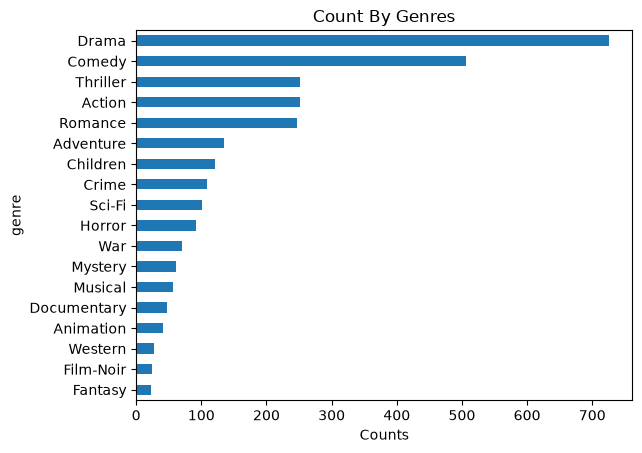

In [14]:
# Q1: your code here
genres_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
genres_df.shape
genres_df.head()
a = genres_df.groupby('genre')['movie_id'].nunique()
a.sort_values().plot(kind='barh', xlabel='Counts', title='Count By Genres')
print(a.sort_values(ascending=False))

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_
The genre that dominates is Drama which is in 725 movies, i counted how the seperaate genres per movie so a single movies covers numerous genres

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

genre
Film-Noir      3.921523
War            3.815812
Documentary    3.688172
Drama          3.687329
Mystery        3.638132
Crime          3.632278
Romance        3.621705
Western        3.613269
Animation      3.579883
Sci-Fi         3.560723
Musical        3.521397
Thriller       3.509007
Adventure      3.503527
Action         3.480245
Comedy         3.393993
Children       3.354654
Horror         3.290389
Fantasy        3.215237
Name: mean, dtype: float64


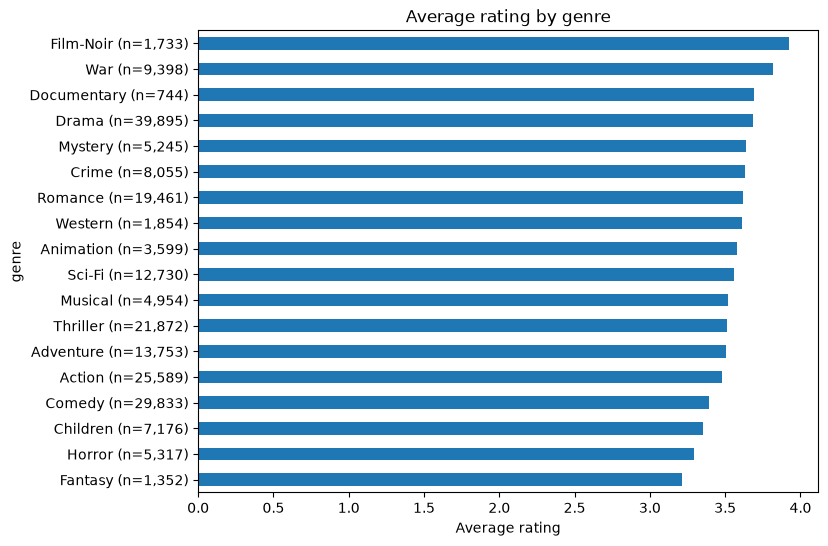

In [ ]:
# Q2: your code here
average_ratings = df.assign(genre=df['genres'].str.split('|')).explode('genre')
a = average_ratings.groupby('genre')['rating'].agg(['mean', 'count'])
s = a.sort_values('mean')

labels = [f"{genre} (n={count:,})" for genre, count in zip(s.index, s['count'])]

ax = s['mean'].plot(kind='barh', figsize=(8, 6))
ax.set_yticklabels(labels)
ax.set_xlabel('Average rating')
ax.set_title('Average rating by genre')


print(a['mean'].sort_values(ascending=False))

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

Top is film noir and lowest is fantasy

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

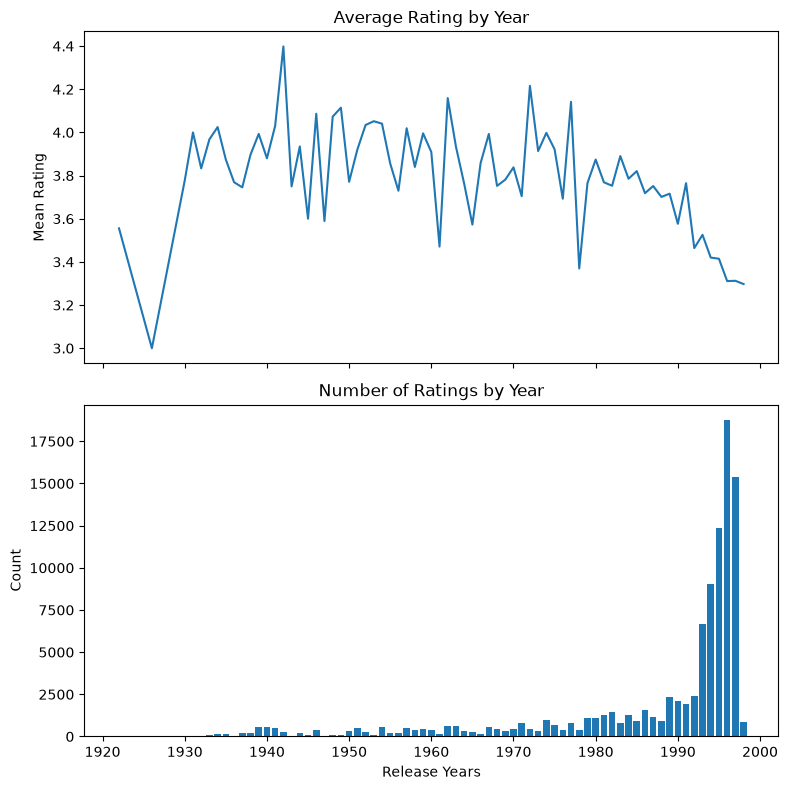

In [48]:
# Q3: your code here
years = df.groupby('year')['rating'].agg(['mean', 'count'])
fig, axes = plt.subplots(2, 1, figsize=(8,8), sharex=True)
axes[0].plot(years.index, years['mean'])
axes[0].set_title("Average Rating by Year")
axes[1].set_xlabel("Release Years")
axes[0].set_ylabel("Mean Rating")

axes[1].bar(years.index, years['count'])
axes[1].set_title("Number of Ratings by Year")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_
Ratings go up and down a lot before like the 1990s but i think the reason the 1990s is on a downward trend/more balanced is just because theres more ratings so the average is based on more than potentially a smaller amount of ratings skewing the average

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

Text(0, 0.5, 'Movie Name')

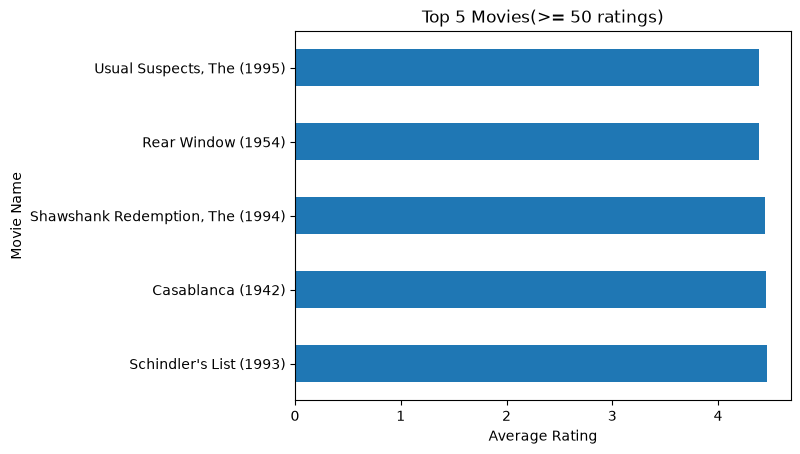

In [57]:
# Q4: your code here
yearGreater = df.groupby('title')['rating'].agg(['mean', 'count'])
ratingsCount = yearGreater[yearGreater['count'] >= 150]
ratingsCount = ratingsCount.sort_values('mean', ascending=False)
ratingsCount = ratingsCount.head(5)

ax = ratingsCount['mean'].plot(kind="barh", title='Top 5 Movies(>= 50 ratings)')
ax.set_xlabel("Average Rating")
ax.set_ylabel("Movie Name")

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_
Curr list:
Wallace & Gromit
Casablanca
Wrong Trousers
Schindler
Close
150+
Only ones that stayed are Casablanca and Schindlers list small samples usually have a less accurate rating

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: I just asked it to create a dashboard to display charts
- AI's first attempt: Pretty poor interface not very visually appealing
- What I changed (or accepted without checking): I changed the way it displayed charts into a scroll page instead of clicking through tabs and altered the accent colors

**Prompt 2**
- What I asked: I asked it to fix the range entry for the ratings
- AI's first attempt: Fixed it pretty well I didnt change anything
- What I changed (or accepted without checking):

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Shows counts by genre not including duplicates but also shows how many genres each movie has
- I say: Only shows counts by genre uniquely 
- Same? (yes / partly / no): partly
- If different, why? I dont show how many genres each movie covers

**Q2**
- Dashboard says: Scatter plot with error bars
- I say: bar chart with ratings and count
- Same? (yes / partly / no): no
- If different, why? Just different visions

**Q3**
- Dashboard says: 2 charts top bottom one with years on a bar chart and then another with scattered ratings
- I say: bottom chart with years and then line chart to show average of years
- Same? (yes / partly / no): no
- If different, why? I think line is better for average of years cause its easier to see a trend

**Q4**
- Dashboard says: Top movies with dot chart
- I say: I use bar chart same top 5
- Same? (yes / partly / no): partly?
- If different, why? Different chart types same methology

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontial bar 
- Chart I used: Horizontial bar
- Which communicates the answer better, and why? Both are same

**Q2**
- Chart the dashboard used: Like a scatter with deviation lines for each part
- Chart I used: Horizontial Bar
- Which communicates the answer better, and why? Id say the chart one it overall looks very clean and shows the low and high end of ratings for each genre

**Q3**
- Chart the dashboard used: vertical bar but dot/scatter plot
- Chart I used:Line and vertical bars
- Which communicates the answer better, and why? I think line is much better since you can see the trend properly and dots kinda leave you overanalyzing the chart

**Q4**
- Chart the dashboard used: dot chart
- Chart I used:Horizontial bar
- Which communicates the answer better, and why? since its only 5 ratings the dot chart id say is better since it shows the differences between ratings better

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week